In [1]:
import os,re
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import matplotlib.pyplot as plt
from scipy.stats import mode
from tqdm.auto import tqdm
import warnings
warnings.simplefilter("ignore")
def split_umap(adata, split_by, ncol=3, nrow=None, **kwargs):
    categories = adata.obs[split_by].cat.categories
    if nrow is None:
        nrow = int(np.ceil(len(categories) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(5*ncol, 5*nrow))
    axs = axs.flatten()
    for i, cat in enumerate(categories):
        ax = axs[i]
        sc.pl.umap(adata[adata.obs[split_by] == cat], ax=ax, show=False, title=cat, **kwargs)
    plt.tight_layout()

In [22]:
# Read the .h5ad file containing the single-cell RNA-seq data
adata = sc.read_h5ad("nRNA_keep3Animal_1stQC_regMito_bbknn.h5ad")
adata

AnnData object with n_obs × n_vars = 312321 × 3000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'doublet_score', 'percent.mt', 'Exprlevel', 'SampleName', 'BrainRegion', 'Animal', 'Source', 'Date', 'Submitter', 'CNGB_No.', 'Matrix_Directory', 'louvain'
    var: 'names', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'hvg', 'log1p', 'louvain', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

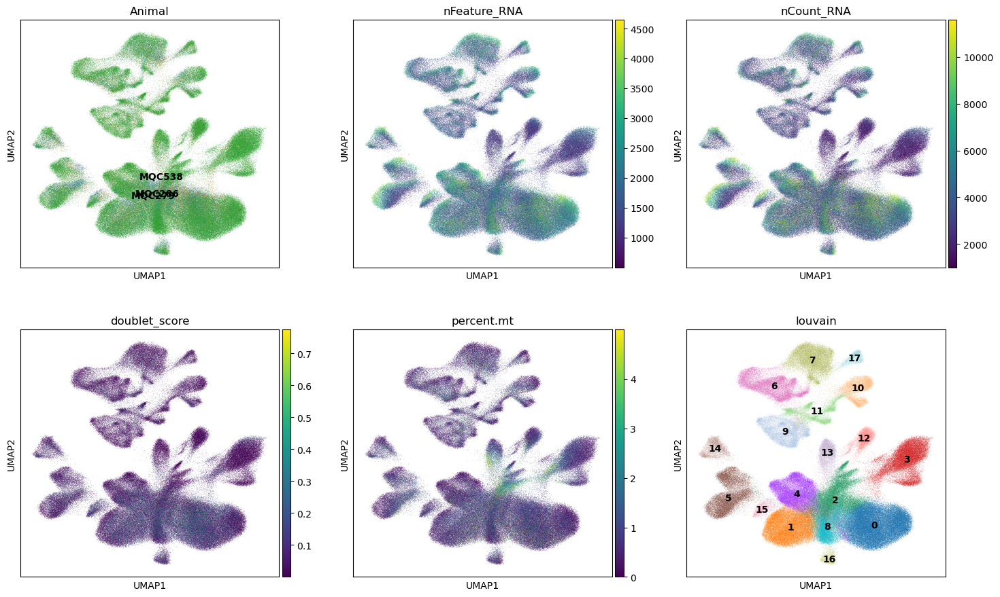

In [8]:
# UMAP visualization of some quality control index
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color = ["Animal","nFeature_RNA","nCount_RNA","doublet_score", "percent.mt","louvain"],ncols=3,legend_loc = "on data")

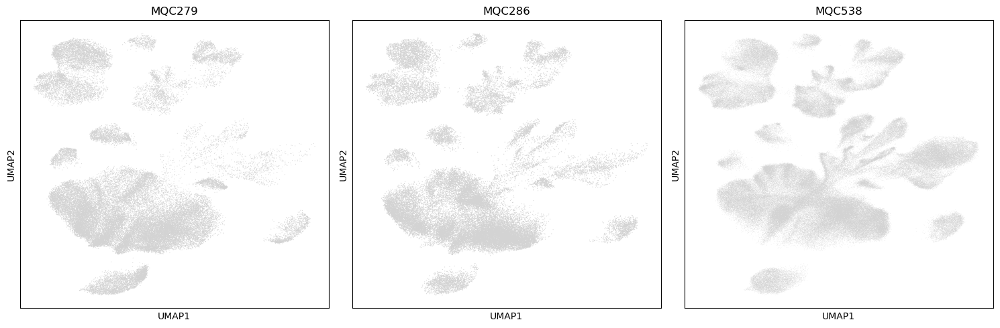

In [4]:
# UMAP visualization of some quality control index
split_umap(adata, "Animal", ncol=3)

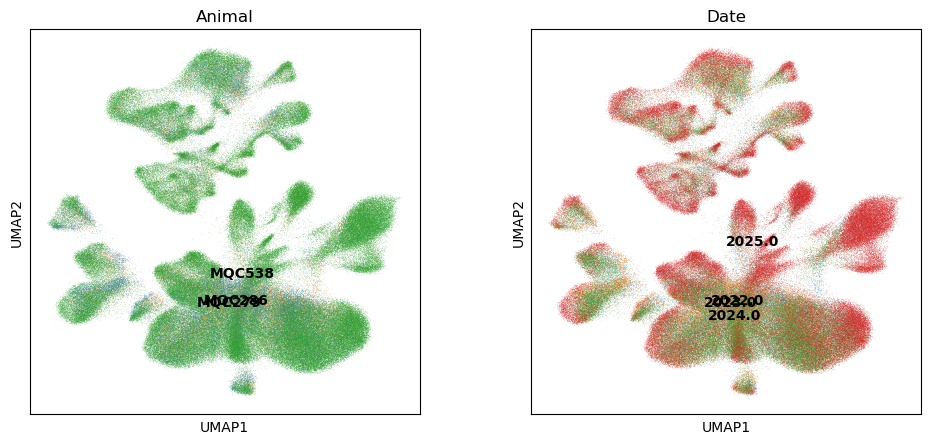

In [10]:
# UMAP visualization of some quality control index
adata.obs["Date"] = adata.obs["Date"].astype("str")
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color = ["Animal","Date"],ncols=3,legend_loc = "on data")

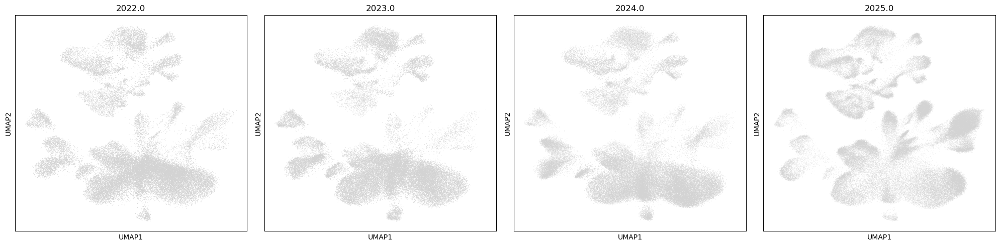

In [9]:
# UMAP visualization of some quality control index
split_umap(adata, "Date", ncol=4)

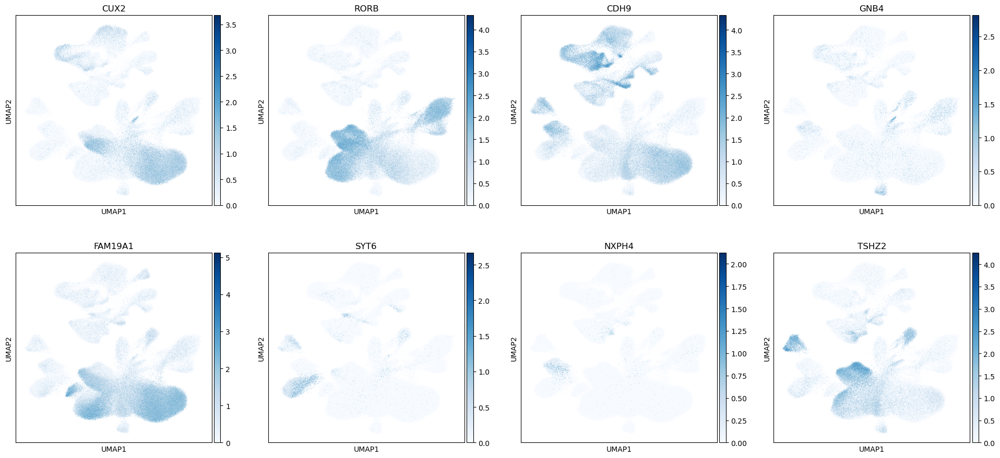

In [129]:
# marker gene expression inspection
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color = ['CUX2','RORB','CDH9','GNB4','FAM19A1','SYT6','NXPH4','TSHZ2'],legend_loc = "on data", cmap= "Blues", size = 1)

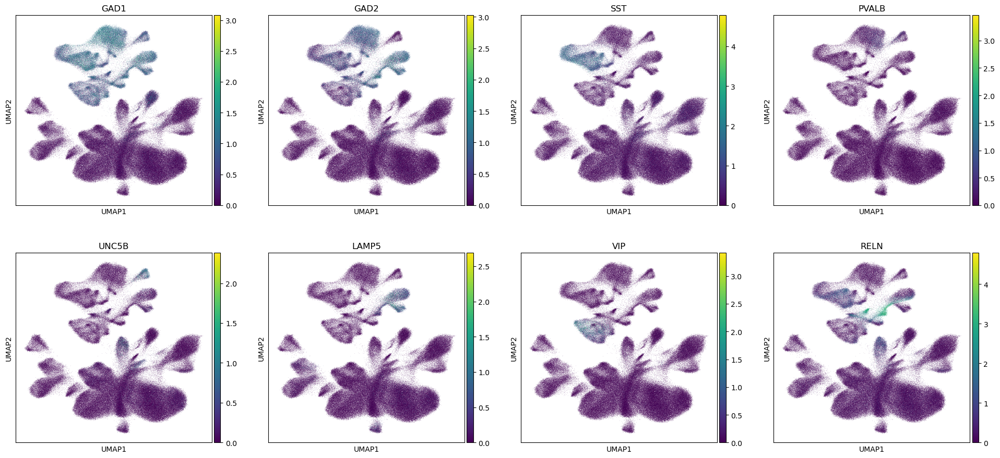

In [13]:
# marker gene expression inspection
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color = ['GAD1','GAD2','SST','PVALB','UNC5B','LAMP5','VIP','RELN'],legend_loc = "on data")

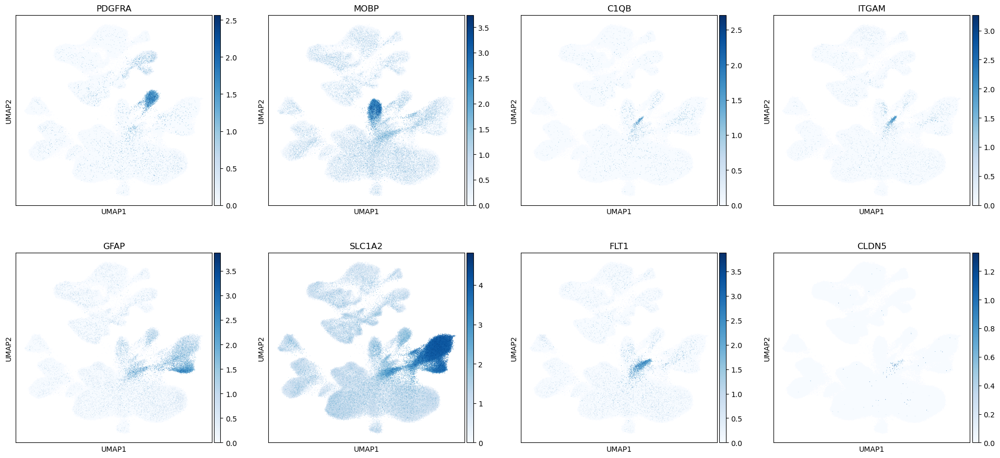

In [67]:
# marker gene expression inspection
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color = ['PDGFRA','MOBP','C1QB',"ITGAM","GFAP",'SLC1A2','FLT1',"CLDN5"],legend_loc = "on data", cmap= "Blues", size = 2)

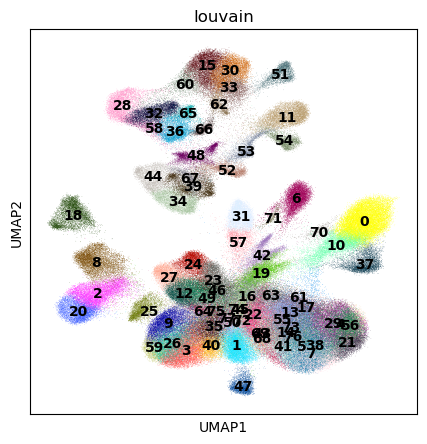

In [44]:
# Inspection of super-clustering results
sc.tl.louvain(adata, resolution = 7)
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color = ['louvain'],legend_loc = "on data")

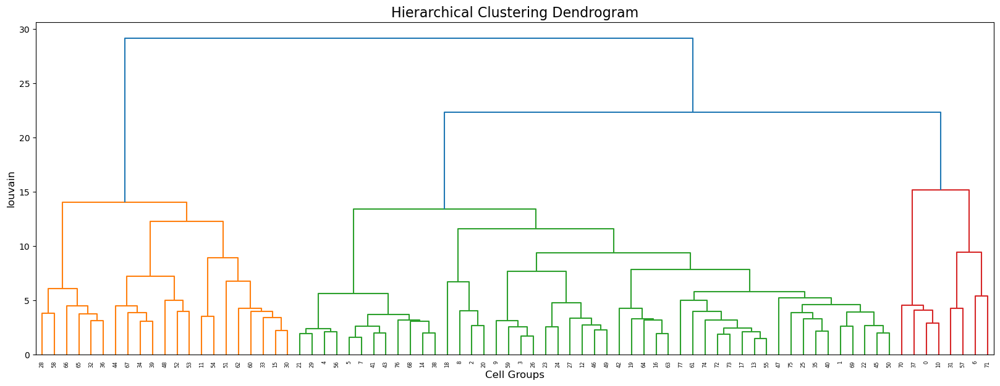

In [57]:
# Inspection of super-clustering results
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

data = pd.DataFrame(adata.obsm['X_pca'], index=adata.obs.index)
cell_groups = adata.obs['louvain']
data = data.groupby(cell_groups).mean()
Z = linkage(data, method='ward')

plt.figure(figsize=(20, 7))
dendrogram(Z, labels=data.index, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram', fontsize=16)
plt.xlabel('Cell Groups', fontsize=12)
plt.ylabel('louvain', fontsize=12)
plt.show()

### Annotate Major Cell Classes Based on Key Markers and Clustering Results

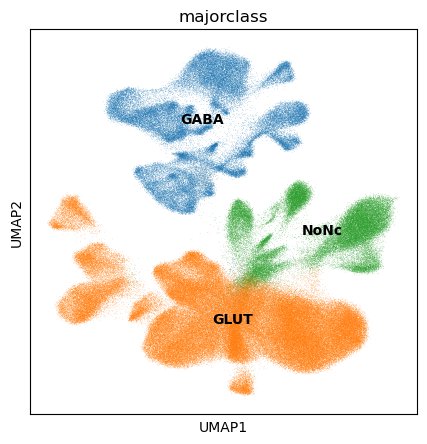

In [68]:
AnnotList = {
    'GLUT': ["21","29","4","56","5","7","41","43","76","68","14","38","18","8","2","20","9","59","3","26","23","24","27","12","46","49","64","16","63","77","61","74","72","73","17","13","55","47","75","25","35","40","1","69","22","45","50"],
    'GABA': ["28","58","66","65","32","36","44","67","34","39","48","52","53","11","54","51","62","60","33","15","30"],
    'NoNc': ["70","37","0","10","31","57","6","71","19","42"]
}
mapping_dict = {vi: k  for k, v in AnnotList.items() for vi in v}
adata.obs['majorclass'] = adata.obs['louvain'].map(mapping_dict)
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata, color=["majorclass"],  legend_loc = "on data")

### Annotate Glutamatergic Neuron Subclasses Using Specific Markers and Clustering Analysis

In [69]:
adata_ex = adata[adata.obs["majorclass"] == "GLUT"].copy()

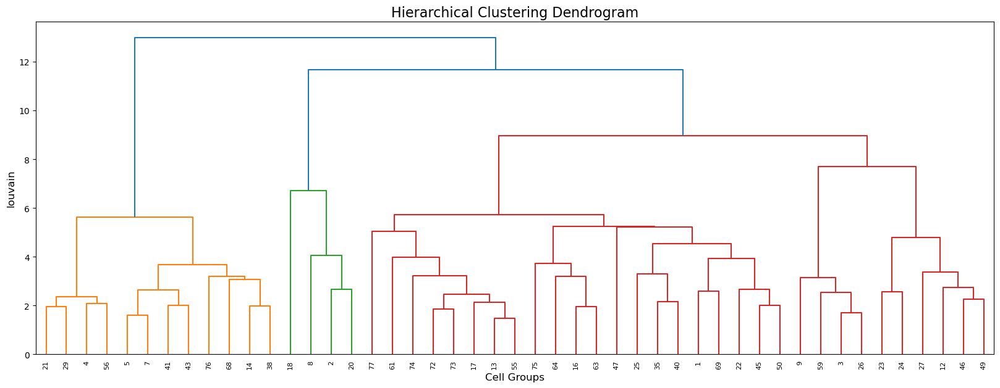

In [70]:
data = pd.DataFrame(adata_ex.obsm['X_pca'], index=adata_ex.obs.index)
cell_groups = adata_ex.obs['louvain']
data = data.groupby(cell_groups).mean()
Z = linkage(data, method='ward')

plt.figure(figsize=(20, 7))
dendrogram(Z, labels=data.index, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram', fontsize=16)
plt.xlabel('Cell Groups', fontsize=12)
plt.ylabel('louvain', fontsize=12)
plt.show()

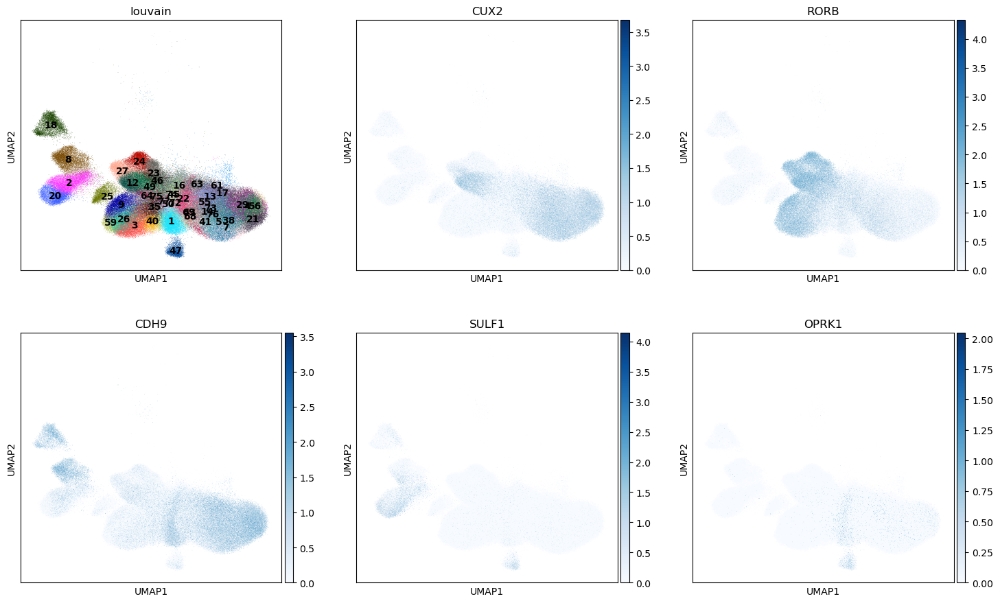

In [130]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_ex, color = ['louvain','CUX2','RORB','CDH9',"SULF1","OPRK1"],legend_loc = "on data",ncols= 3, cmap= 'Blues')

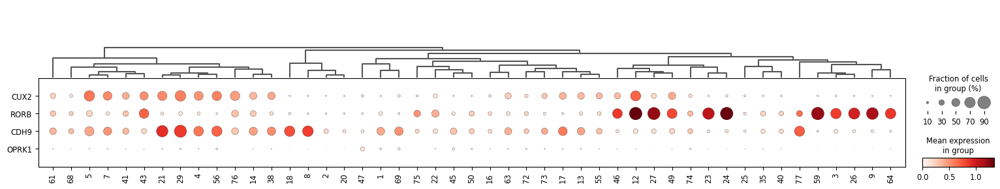

In [84]:
with plt.rc_context({"figure.figsize": (10, 5)}):
    sc.pl.dotplot(adata_ex,["CUX2","RORB",'CDH9',"OPRK1"], groupby='louvain', dendrogram= True, swap_axes= True)

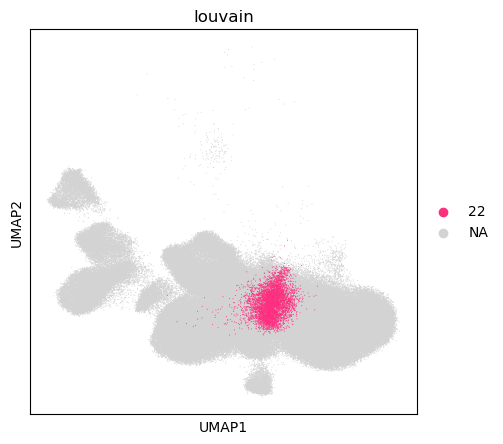

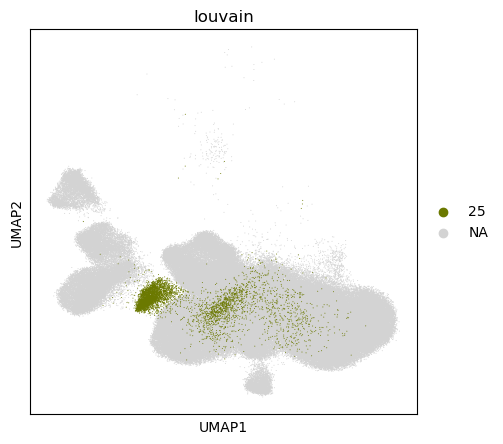

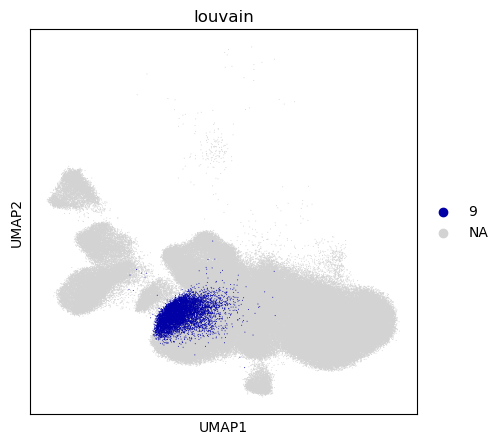

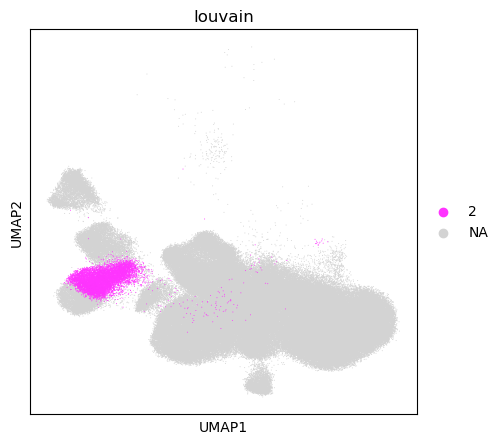

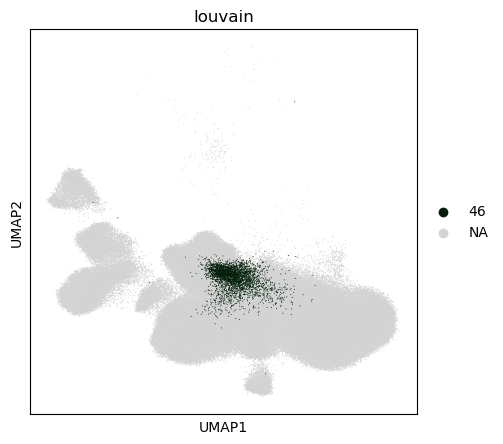

...

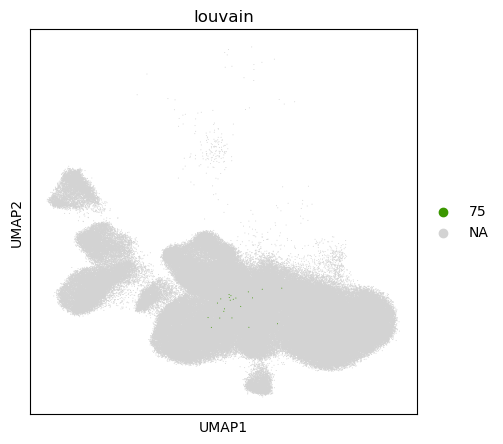

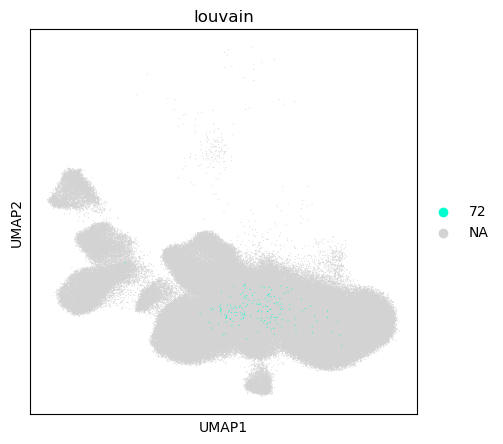

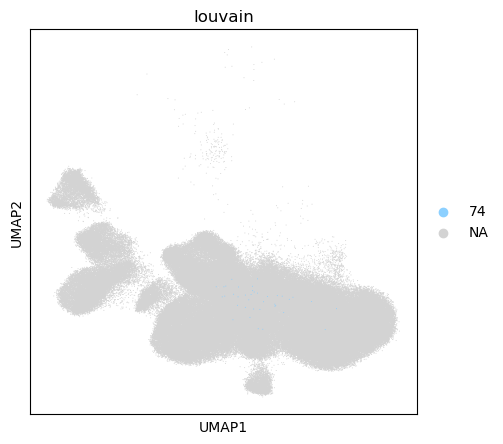

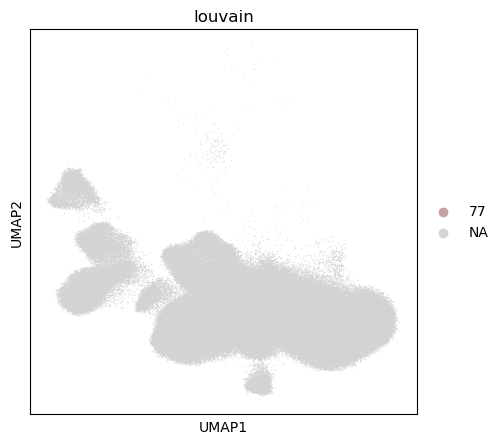

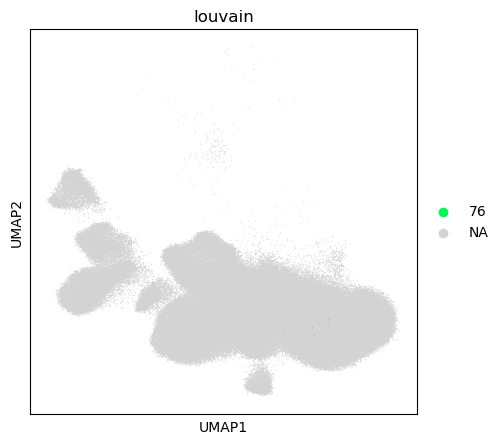

In [76]:
for i in adata_ex.obs.louvain.unique().astype("str"):
    with plt.rc_context({"figure.figsize": (5, 5)}):
        sc.pl.umap(adata_ex, color=["louvain"], groups=i, s = 2)
        
### NOTE: Noise Clusters Identified - Cluster IDs: ["61","69","73","68","75","72","74","77","76"]

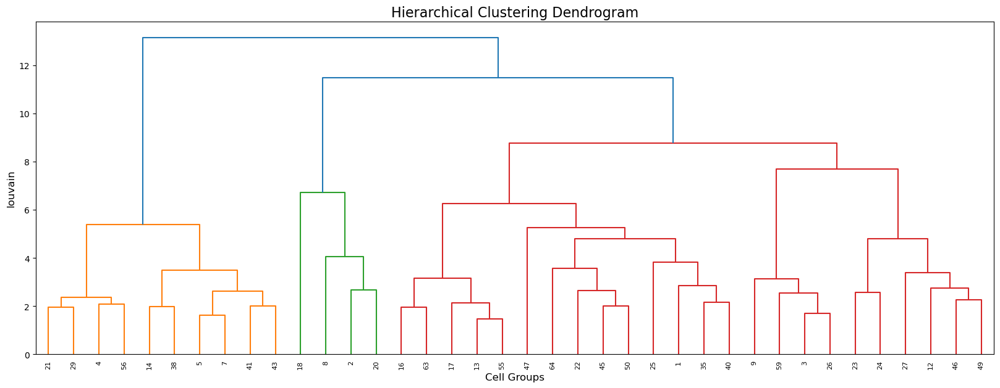

In [96]:
data = pd.DataFrame(adata_ex.obsm['X_pca'], index=adata_ex.obs.index)
cell_groups = adata_ex.obs['louvain']
data = data.groupby(cell_groups).mean()
data = data.drop(index = ["61","69","73","68","75","72","74","77","76"])
Z = linkage(data, method='ward')

plt.figure(figsize=(20, 7))
dendrogram(Z, labels=data.index, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram', fontsize=16)
plt.xlabel('Cell Groups', fontsize=12)
plt.ylabel('louvain', fontsize=12)
plt.show()

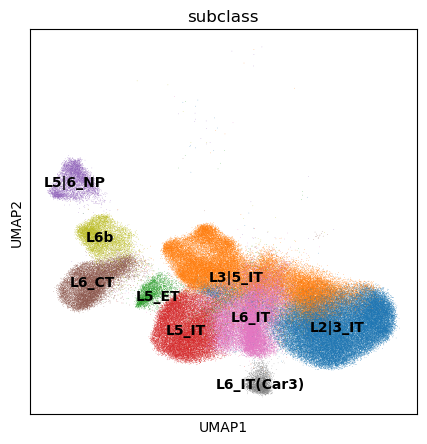

In [101]:
AnnotList = {
    'L2|3_IT': ["21","29","4","56","14","38","5","7","41","43"],
    'L3|5_IT': ["16","63","17","13","55","23","24","27","12","46","49"],
    'L5_IT': ["9","59","3","26"],
    'L6_IT': ["64","22","45","50","1","35","40"],
    'L6_IT(Car3)': ["47"],
    'L5|6_NP': ["18"],
    'L6_CT': ["2","20"],
    'L6b': ["8"],
    'L5_ET': ["25"],
    'NOISE' : ["61","69","73","68","75","72","74","77","76"]
}
mapping_dict = {vi: k  for k, v in AnnotList.items() for vi in v}
adata_ex.obs['subclass'] = adata_ex.obs['louvain'].map(mapping_dict)
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_ex[adata_ex.obs["subclass"] != "NOISE"], color=["subclass"],  legend_loc = "on data")

In [102]:
adata_ex.obs.to_csv("GLUT_1stAnnot.csv")

### Annotate GABAergic Neuron Subclasses Using Specific Markers and Clustering Analysis

In [23]:
adata_in = adata[adata.obs["majorclass"] == "GABA"].copy()

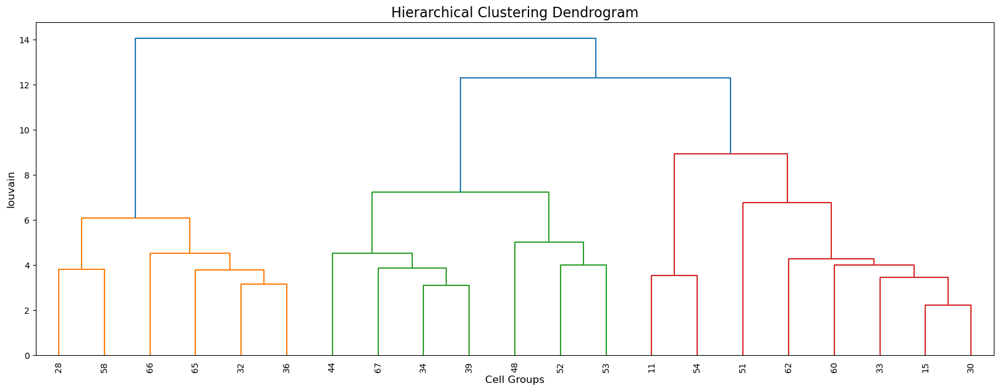

In [104]:
data = pd.DataFrame(adata_in.obsm['X_pca'], index=adata_in.obs.index)
cell_groups = adata_in.obs['louvain']
data = data.groupby(cell_groups).mean()
Z = linkage(data, method='ward')

plt.figure(figsize=(20, 7))
dendrogram(Z, labels=data.index, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram', fontsize=16)
plt.xlabel('Cell Groups', fontsize=12)
plt.ylabel('louvain', fontsize=12)
plt.show()

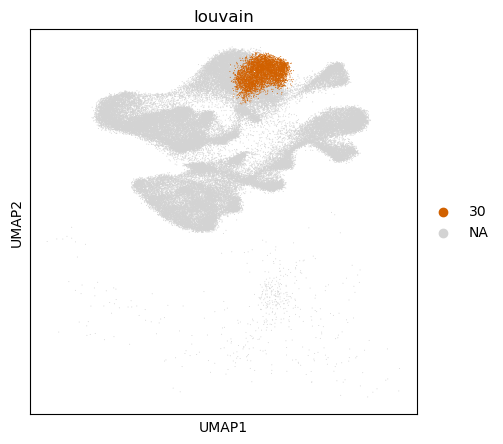

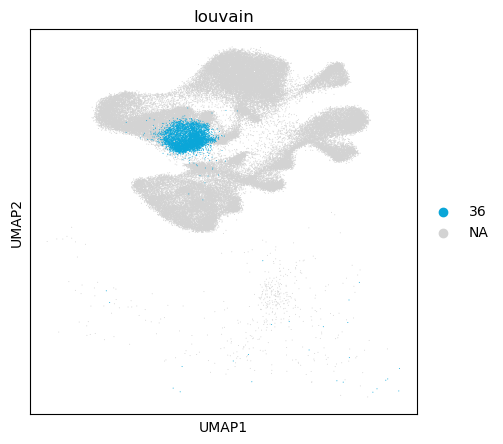

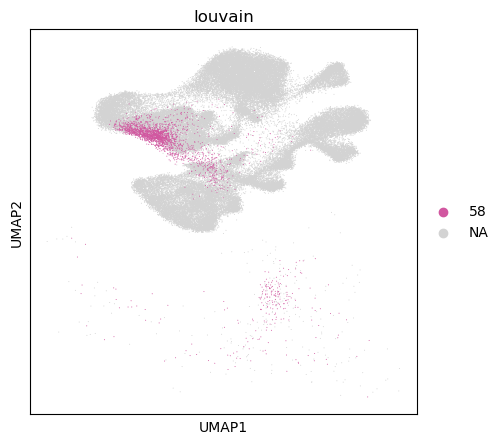

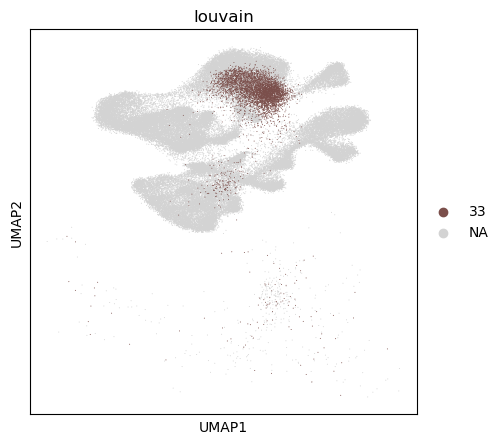

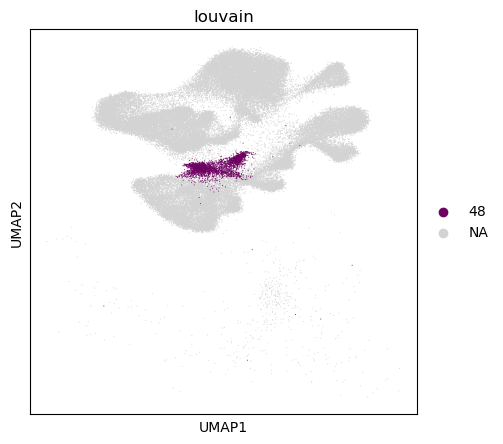

...

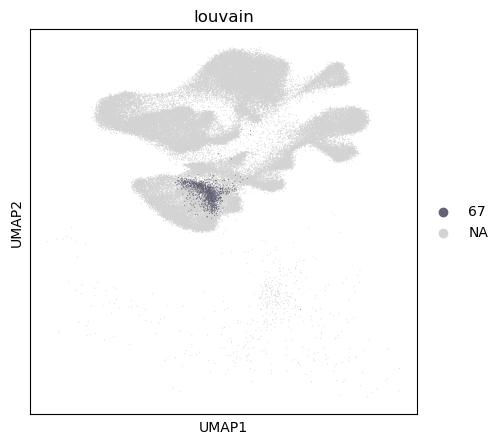

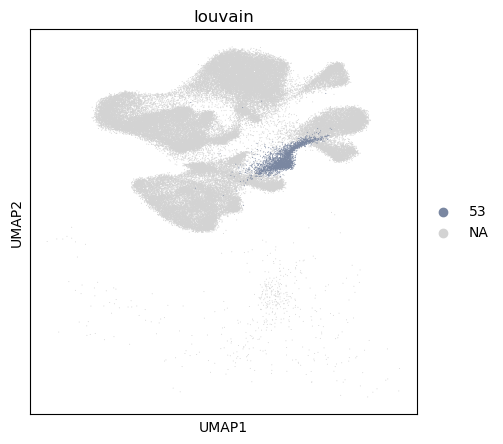

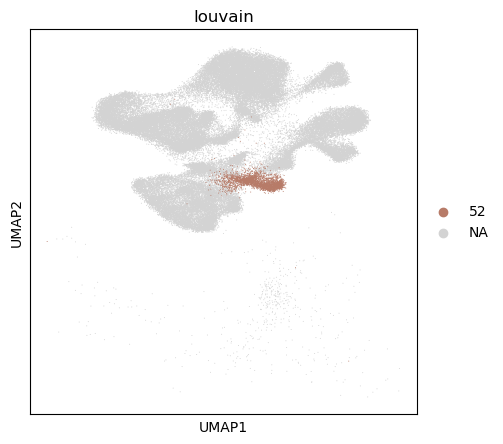

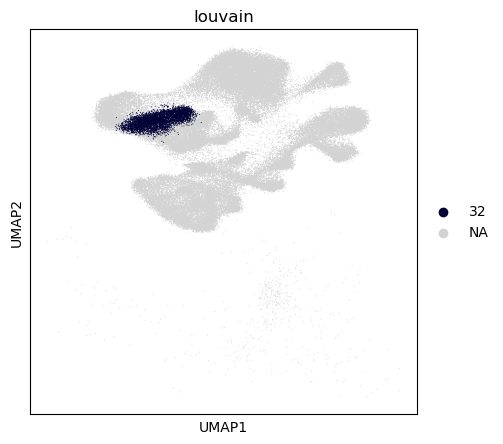

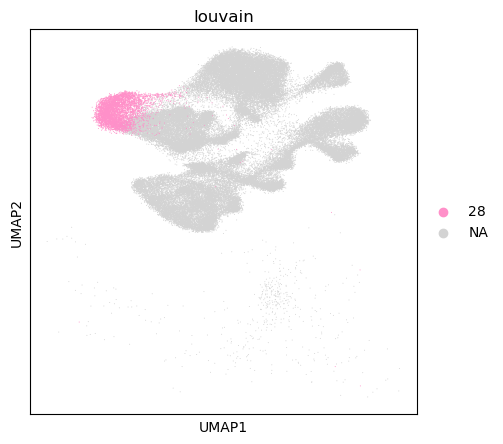

In [105]:
for i in adata_in.obs.louvain.unique().astype("str"):
    with plt.rc_context({"figure.figsize": (5, 5)}):
        sc.pl.umap(adata_in, color=["louvain"], groups=i, s = 2)
        
### NOTE: Noise Clusters Identified - Cluster IDs: [""]

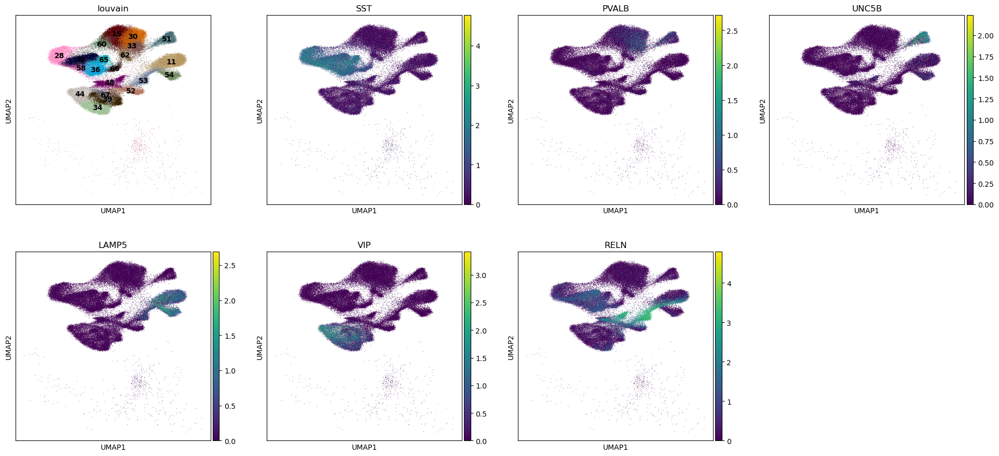

In [107]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_in, color = ['louvain','SST','CHODL','PVALB','UNC5B','LAMP5','VIP','RELN'],legend_loc = "on data")

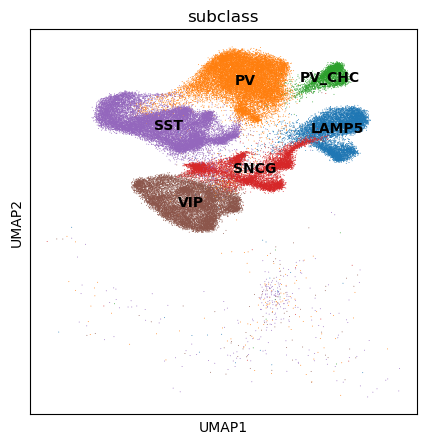

In [108]:
AnnotList = {
    'SST': ["28","58","66","65","32","36"],
    'PV': ["62","60","33","15","30"],
    'PV_CHC': ['51'],
    'VIP': ["44","67","34","39"],
    'SNCG': ["48","52","53"],
    'LAMP5': ["11","54"]
}
mapping_dict = {vi: k  for k, v in AnnotList.items() for vi in v}
adata_in.obs['subclass'] = adata_in.obs['louvain'].map(mapping_dict)
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_in, color=["subclass"],  legend_loc = "on data")

In [109]:
adata_in.obs.to_csv("GABA_1stAnnot.csv")

### Annotate None-Neuron Subclasses Based on Specific Markers and Clustering Analysis

In [110]:
adata_nc = adata[adata.obs["majorclass"] == "NoNc"].copy()

In [111]:
sc.tl.louvain(adata_nc, resolution = 3)

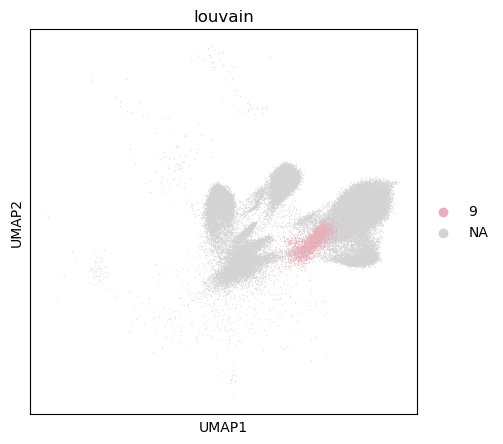

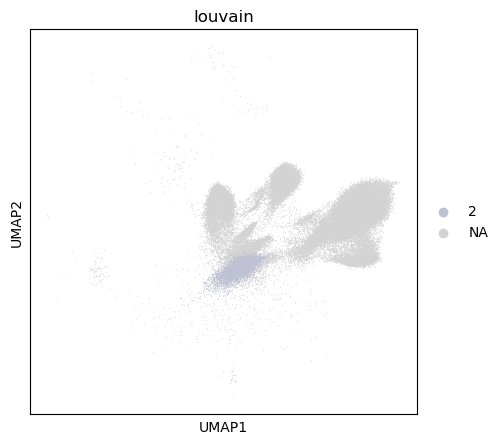

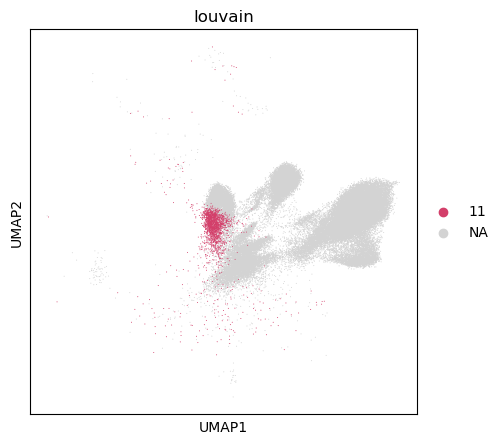

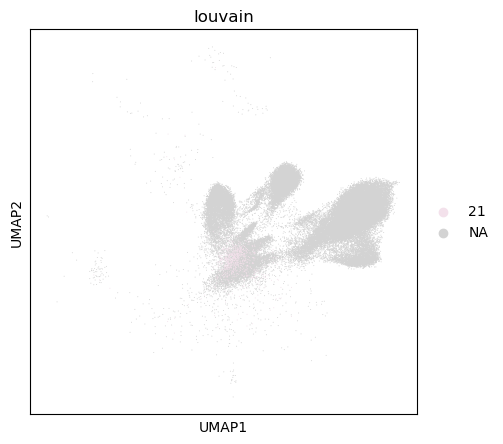

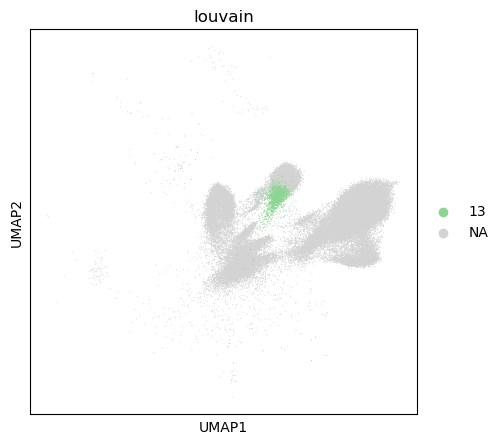

...

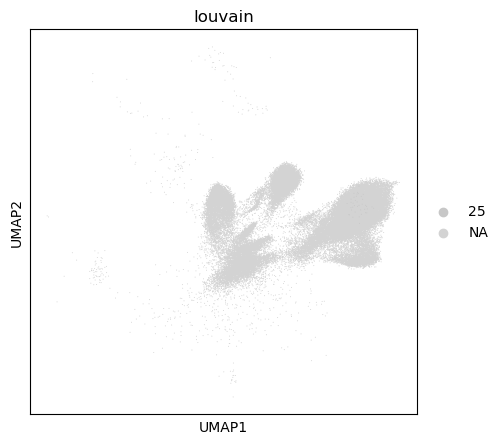

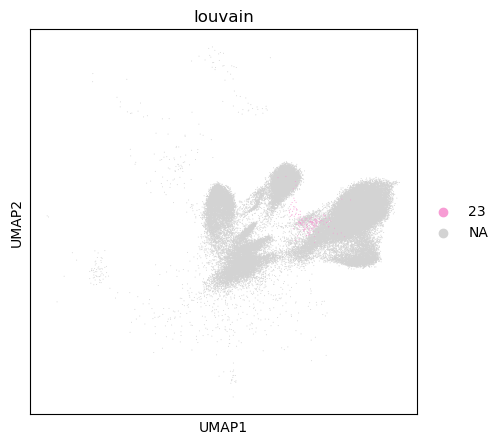

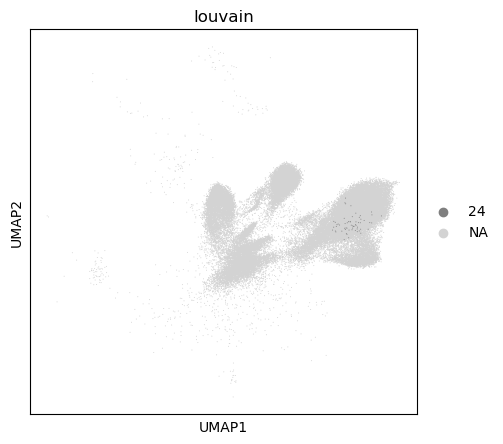

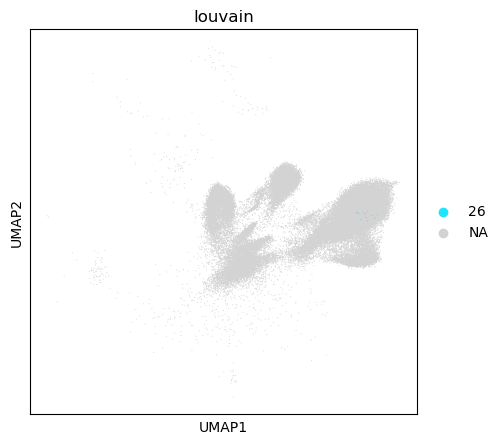

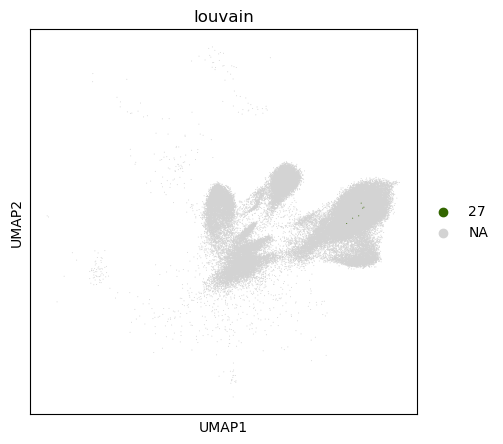

In [114]:
for i in adata_nc.obs.louvain.unique().astype("str"):
    with plt.rc_context({"figure.figsize": (5, 5)}):
        sc.pl.umap(adata_nc, color=["louvain"], groups=i, s = 2)
        
### NOTE: Noise Clusters Identified - Cluster IDs:["23","25","24","26","27"]

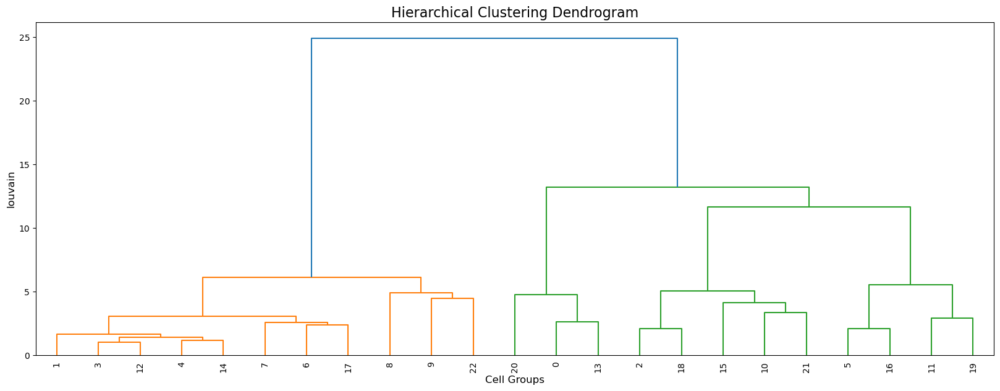

In [116]:
data = pd.DataFrame(adata_nc.obsm['X_pca'], index=adata_nc.obs.index)
cell_groups = adata_nc.obs['louvain']
data = data.groupby(cell_groups).mean()
data = data.drop(index = ["23","25","24","26","27"])

Z = linkage(data, method='ward')

plt.figure(figsize=(20, 7))
dendrogram(Z, labels=data.index, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram', fontsize=16)
plt.xlabel('Cell Groups', fontsize=12)
plt.ylabel('louvain', fontsize=12)
plt.show()

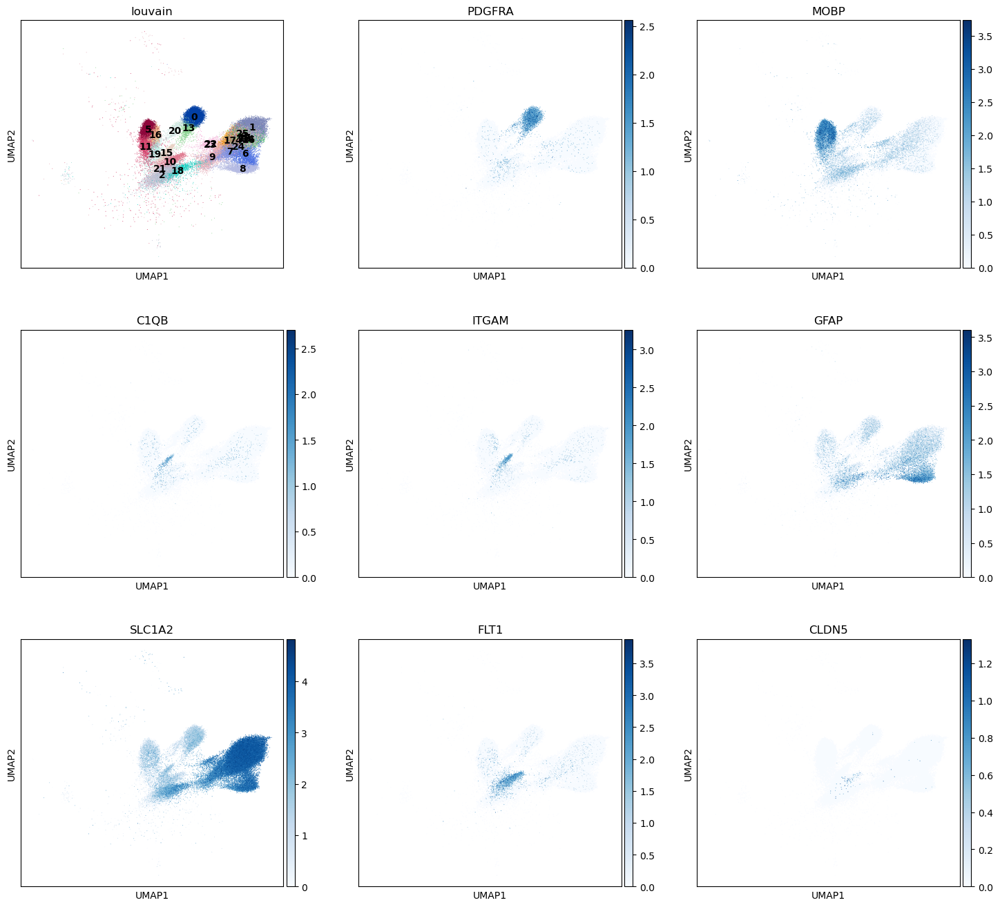

In [131]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_nc, color = ["louvain",'PDGFRA','MOBP','C1QB',"ITGAM","GFAP",'SLC1A2','FLT1',"CLDN5"],legend_loc = "on data", cmap= "Blues",ncols = 3, size = 2)

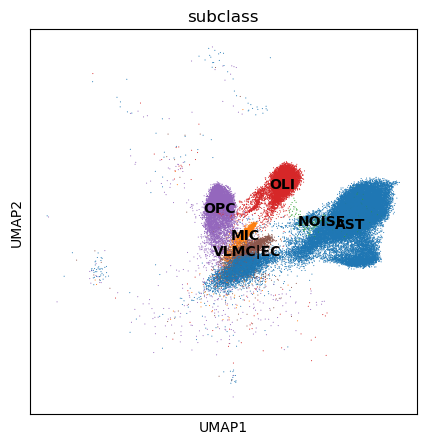

In [117]:
AnnotList = {
    'OLI': ["0","20","13"],
    'OPC': ["5","16","11","19"],
    'MIC': ["15"],
    'AST': ["1","3","12","4","14","7","6","17","8","9","22","2","18"],
    'VLMC|EC': ["10","21"],
    'NOISE': ["23","25","24","26","27"]
    
}

mapping_dict = {vi: k  for k, v in AnnotList.items() for vi in v}
adata_nc.obs['subclass'] = adata_nc.obs['louvain'].map(mapping_dict)
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_nc, color=["subclass"],  legend_loc = "on data")

In [118]:
adata_nc.obs.to_csv("NoNc_1stAnnot.csv")

### Combine Annotation

In [125]:
adata.obs = pd.concat([adata_ex.obs, adata_in.obs, adata_nc.obs], ignore_index=False).reindex(adata.obs_names)

In [159]:
adata_clean = adata[adata.obs['subclass'] != "NOISE"].copy()

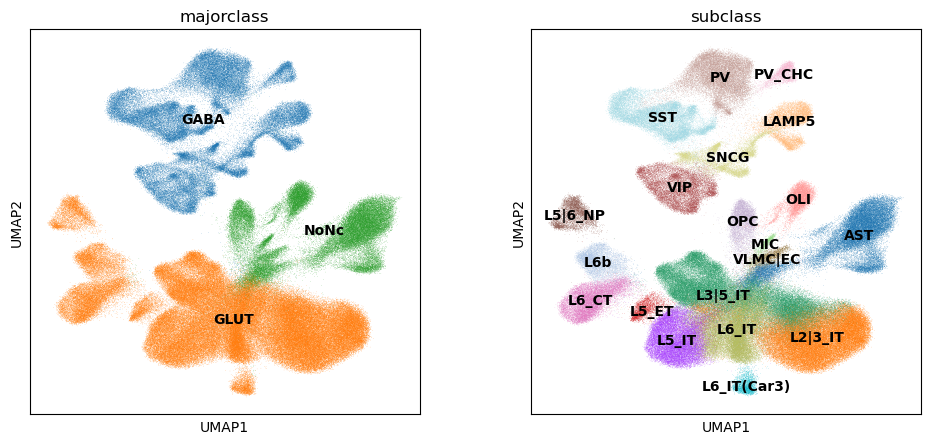

In [128]:
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_clean, color=["majorclass","subclass"],  legend_loc = "on data")

In [133]:
adata_clean.write_h5ad("nRNA_keep3Animal_1stQC_regMito_withAnnot.h5ad")

#### Superclustering for Celltype Identification

In [138]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from joblib import Parallel, delayed
from scipy.stats import gmean
import scanpy as sc
import anndata as ad
np.random.seed(None)

def _evaluate_f1(X_train, X_test, y_train, y_test):
    """Train a Random Forest model and evaluate its F1 score.

    Args:
        X_train: Training feature data.
        X_test: Test feature data.
        y_train: Training labels.
        y_test: Test labels.

    Returns:
        Minimum F1 score.
    """
    rf = RandomForestClassifier(n_estimators=500, random_state=42, class_weight='balanced')
    rf.fit(X_train, y_train)
    rf_report = classification_report(y_test, rf.predict(X_test), output_dict=True)
    return pd.DataFrame(rf_report).transpose()['f1-score'].min()

def _sample_evaluate(clean_adata, N = 100):
    """Sample cells from each cluster and evaluate F1 score.

    Args:
        clean_adata: Processed AnnData object.

    Returns:
        Calculated F1 score.
    """
    sampled_cells = []
    for cluster in clean_adata.obs['louvain_clusters'].unique():
        cells_in_cluster = clean_adata[clean_adata.obs['louvain_clusters'] == cluster].copy()
        sampled_cells.append(cells_in_cluster[np.random.choice(cells_in_cluster.n_obs, min(cells_in_cluster.n_obs, N), replace=False)])

    sampled_adata = ad.concat(sampled_cells, index_unique="_", join="outer")
    # Extract features and labels
    X_train, X_test, y_train, y_test = train_test_split(
        sampled_adata.obsm["X_pca"], sampled_adata.obs['louvain_clusters'], test_size=0.3, random_state=42
    )
    # Apply oversampling to training data
    smote = SMOTE(random_state=42)
    if len(np.unique(y_train)) > 1:
        X_train, y_train = smote.fit_resample(X_train, y_train)
    
    return _evaluate_f1(X_train, X_test, y_train, y_test)

def SuperClusterValidator(adata, cut_score = 0.6, **kwargs):
    """Evaluate cluster stability at different resolutions.

    Args:
        adata: Input AnnData object.

    Returns:
        Cleaned AnnData object with clusters at the optimal resolution.
    """
    previous_result = None
    cluster_counts = 0  # Set initial cluster count to 0
    for res in np.arange(1, 8.1, 0.25):
        sc.tl.louvain(adata, resolution=res, key_added='louvain_clusters')
        # Remove noise samples where N(louvain_clusters) < 30
        valid_clusters = adata.obs['louvain_clusters'].value_counts()
        valid_clusters = valid_clusters[valid_clusters > 30].index

        if len(valid_clusters) <= cluster_counts: 
            continue
        else:
            cluster_counts = len(valid_clusters)
        
        clean_adata = adata[adata.obs['louvain_clusters'].isin(valid_clusters)].copy()
        # Calculate the average minimum F1 score over 100 sampled datasets at current resolution
        avg_min_F1 = np.mean(Parallel(n_jobs = -1, prefer="processes")(delayed(_sample_evaluate)(clean_adata) for _ in range(100)))
        if avg_min_F1 > cut_score:
            previous_result = clean_adata.obs.copy()
        else:
            return previous_result if previous_result is not None else clean_adata.obs.copy()

In [135]:
### Loading Data
adata_clean = sc.read_h5ad("nRNA_keep3Animal_1stQC_regMito_withAnnot.h5ad")
adata_clean

AnnData object with n_obs × n_vars = 308324 × 3000
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'doublet_score', 'percent.mt', 'Exprlevel', 'SampleName', 'BrainRegion', 'Animal', 'Source', 'Date', 'Submitter', 'CNGB_No.', 'Matrix_Directory', 'louvain', 'majorclass', 'subclass'
    var: 'names', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'hvg', 'log1p', 'louvain', 'neighbors', 'pca', 'umap', 'Animal_colors', 'louvain_colors', 'Date_colors', 'majorclass_colors', 'subclass_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [ ]:
rslt_list = []
for i in adata_clean.obs["subclass"].unique():
    adata_temp = adata_clean[adata_clean.obs['subclass'] == i].copy()
    
    # Re-encode the minimum cluster labels
    tmpt_obs = SuperClusterValidator(adata=adata_temp)
    tmpt_obs['louvain_clusters'] = tmpt_obs['louvain_clusters'].astype(str).apply(lambda x: str(x).zfill(2))
    tmpt_obs['cellcluster'] = tmpt_obs['subclass'].astype(str) + '.' + tmpt_obs['louvain_clusters'].astype(str)
    rslt_list.append(tmpt_obs)

# Merge the results into a new dataframe
new_obs = pd.concat(rslt_list, ignore_index=False).reindex(adata_clean.obs_names)
del new_obs["louvain_clusters"]

In [161]:
len(new_obs["cellcluster"].unique())

163

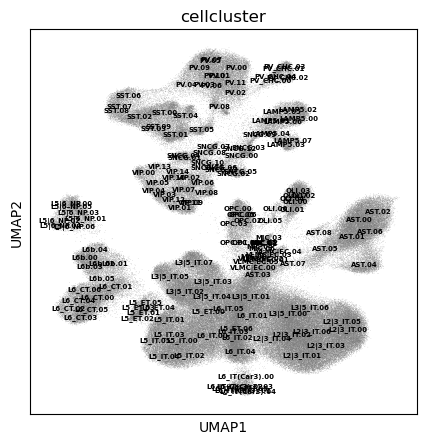

In [167]:
adata_clean.obs = new_obs
adata_clean = adata_clean[adata_clean.obs['cellcluster'].notna(), :]
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_clean, color=["cellcluster"],  legend_loc = "on data", legend_fontsize= 5)

In [169]:
adata_clean.write_h5ad("nRNA_keep3Animal_1stQC_regMito_withAnnot.h5ad")
adata_clean.obs.to_csv("nRNA_keep3Animal_1stQC_regMito_withAnnot.obs.csv")

### Merge Clusters with Insignificant Differential Gene Scores

In [2]:
from scipy.spatial.distance import cdist
from collections import Counter

def _deScore(adata, clust):
    """Calculate DE score for a given cluster.

    Args:
        adata: Annotated data object.
        clust: Cluster to calculate DE score for.

    Returns:
        Sum of DE scores for significantly differentially expressed genes.
    """
    rank_dt = sc.get.rank_genes_groups_df(adata, group=clust)
    rank_dt['log_pvals'] = -np.log10(rank_dt['pvals_adj'])
    rank_dt['de_score'] = np.abs(rank_dt['logfoldchanges']) * np.minimum(20, rank_dt['log_pvals'])
    sum_descore = rank_dt[rank_dt['pvals_adj'] < 0.05]['de_score'].sum()
    return sum_descore

def get_current_merge(adata, ident, th = 100):
    """Identify clusters to merge based on DE score threshold.

    Args:
        adata: Annotated data object.
        ident: Clustering identification column.
        th: Threshold for DE score.

    Returns:
        List of clusters to merge based on DE score.
    """
    sc.tl.rank_genes_groups(adata, ident, method='wilcoxon')
    score_dict = {clust: _deScore(adata, clust) for clust in adata.obs[ident].unique()}
    need_to_merge = [key for key, value in score_dict.items() if value < th]
    return need_to_merge
    
def find_nearest_cluster(x_pca, labels, val):
    """Find the nearest cluster to a given cluster.

    Args:
        x_pca: PCA-transformed data.
        labels: Cluster labels.
        val: Target cluster to find the nearest cluster to.

    Returns:
        The label of the nearest cluster.
    """
    unique_labels = labels.unique()
    cluster_centers = {clust: x_pca[labels == clust,:].mean(axis=0) for clust in unique_labels}
    
    dist_mtx = pd.DataFrame(
        cdist(np.vstack(cluster_centers.values()), np.vstack(cluster_centers.values()), metric='euclidean'), 
        index=unique_labels, columns=unique_labels
    )
    # Find the closest subclass to the given value (val)
    nearest_cluster = dist_mtx.loc[val].drop(val).idxmin()
    return nearest_cluster

In [26]:
adata_clean = sc.read_h5ad("nRNA_keep3Animal_1stQC_regMito_withAnnot.h5ad")

In [4]:
for subclass in adata_clean.obs.subclass.unique():
    print(f"Iteration: {subclass}")  # Output the current processing subclass
    iteration_counter = 0  # Initialize the iteration counter
    while True:
        adata_ = adata_clean[adata_clean.obs.subclass == subclass,:].copy()
        ### Get the clusters that need to be merged
        need_to_merge = get_current_merge(adata_, "cellcluster", 100)
        if len(need_to_merge) > 0:
            current_merge = np.random.choice(need_to_merge)
        else:
            print(f"No need to merge for subclass {subclass}. Breaking the loop.")
            break
            
        print(f"Merging Iteration: {iteration_counter}")  # Output the current merging iteration count
        # Find the nearest intra-class cluster to merge with the selected cluster (current_merge)
        x_pca = adata_.obsm['X_pca']
        labels = adata_.obs["cellcluster"].values
        nearest_cluster = find_nearest_cluster(x_pca, labels, current_merge)

        mapping_dict = {current_merge: nearest_cluster}
        adata_clean.obs['cellcluster'] = adata_clean.obs['cellcluster'].replace(mapping_dict)  ### Merge and update naming

Iteration: L6_IT
No need to merge for subclass L6_IT. Breaking the loop.
Iteration: L5_ET
No need to merge for subclass L5_ET. Breaking the loop.
Iteration: L5_IT
No need to merge for subclass L5_IT. Breaking the loop.
Iteration: L6_CT
No need to merge for subclass L6_CT. Breaking the loop.
Iteration: AST
No need to merge for subclass AST. Breaking the loop.
Iteration: L3|5_IT
No need to merge for subclass L3|5_IT. Breaking the loop.
Iteration: PV
No need to merge for subclass PV. Breaking the loop.
Iteration: L6b
No need to merge for subclass L6b. Breaking the loop.
Iteration: L2|3_IT
No need to merge for subclass L2|3_IT. Breaking the loop.
Iteration: SST
No need to merge for subclass SST. Breaking the loop.
Iteration: L5|6_NP
No need to merge for subclass L5|6_NP. Breaking the loop.
Iteration: OPC
No need to merge for subclass OPC. Breaking the loop.
Iteration: SNCG
No need to merge for subclass SNCG. Breaking the loop.
Iteration: VLMC|EC
No need to merge for subclass VLMC|EC. Break

In [5]:
### Recode Cell type identity
adata_clean.obs['subclass_group'] = adata_clean.obs.groupby('subclass')['cellcluster'].transform(lambda x: pd.factorize(x)[0] + 1)
adata_clean.obs['subclass_group'] = adata_clean.obs['subclass_group'].astype(str).apply(lambda x: str(x).zfill(2))
adata_clean.obs['cellcluster'] = adata_clean.obs['subclass'].astype(str) + '.' + adata_clean.obs['subclass_group'].astype(str)

In [16]:
adata_clean.obs['cellcluster'].unique().astype(str)

array(['L6_IT.01', 'L5_ET.01', 'L5_IT.01', 'L6_CT.01', 'AST.01',
       'L3|5_IT.01', 'L3|5_IT.02', 'PV.01', 'L6b.01', 'L6_IT.02',
       'L6_IT.03', 'L2|3_IT.01', 'SST.01', 'L6_CT.02', 'SST.02', 'PV.02',
       'L3|5_IT.03', 'L5|6_NP.01', 'AST.02', 'L5_IT.02', 'L6_CT.03',
       'L3|5_IT.04', 'L3|5_IT.05', 'L6_IT.04', 'L5|6_NP.02', 'OPC.01',
       'SNCG.01', 'PV.03', 'VLMC|EC.01', 'L6_IT(Car3).01', 'VIP.01',
       'L3|5_IT.06', 'L6b.02', 'L2|3_IT.02', 'L6_IT.05', 'LAMP5.01',
       'L5|6_NP.03', 'PV.04', 'L6_CT.04', 'L6_IT(Car3).02', 'OLI.01',
       'LAMP5.02', 'PV_CHC.01', 'PV.05', 'L5|6_NP.04', 'SST.03',
       'L2|3_IT.03', 'VIP.02', 'PV.06', 'SNCG.02', 'L6_IT(Car3).03',
       'OPC.02', 'L2|3_IT.04', 'L5_IT.03', 'L2|3_IT.05', 'VLMC|EC.02',
       'L6_IT(Car3).04', 'L5_ET.02', 'L5|6_NP.05', 'L3|5_IT.07', 'OPC.03',
       'PV.07', 'L2|3_IT.06', 'L5_IT.04', 'L6_CT.05', 'LAMP5.03',
       'AST.03', 'OPC.04', 'VIP.03', 'AST.04', 'LAMP5.04', 'L5_ET.03',
       'SST.04', 'VIP.04', 'AS

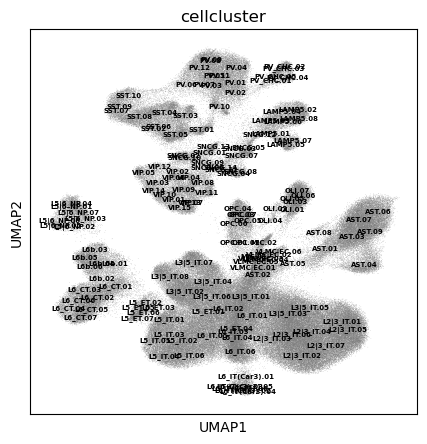

In [9]:
adata_clean = adata_clean[adata_clean.obs['cellcluster'].notna(), :]
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(adata_clean, color=["cellcluster"],  legend_loc = "on data", legend_fontsize= 5)

In [42]:
adata_clean.write_h5ad("nRNA_keep3Animal_finalAnnot.h5ad")

In [35]:
adata_clean.obs = adata_clean.obs.set_index('Unnamed: 0')
adata_clean.obs.index.name = None
adata_clean.obs['UMAP_1'],adata_clean.obs['UMAP_2'] = adata_clean.obsm['X_umap'][:,0], adata_clean.obsm['X_umap'][:,1]
adata_clean.obs.to_csv("nRNA_keep3Animal_finalAnnot.obs.csv")

### Generate Global Confusion Heatmap for Cell Classification

In [18]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from imblearn.over_sampling import SMOTE
from joblib import Parallel, delayed
from scipy.stats import gmean
import scanpy as sc
import anndata as ad
np.random.seed(None)

def _confusion_matrix(X_train, X_test, y_train, y_test, label_order = None):
    rf = RandomForestClassifier(n_estimators=500, random_state=42, class_weight='balanced')
    rf.fit(X_train, y_train)
    # Predict and generate confusion matrix
    y_pred = rf.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels= label_order)
    # Normalize by row (so that the sum of each row is 1)
    cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)
    return cm_normalized

def _sample_data(adata, N = 100, **kwargs):
    sampled_cells = []
    for cluster in adata.obs['cellcluster'].unique():
        cells_in_cluster = adata[adata.obs['cellcluster'] == cluster].copy()
        sampled_cells.append(cells_in_cluster[np.random.choice(cells_in_cluster.n_obs, min(cells_in_cluster.n_obs, N), replace=False)])

    sampled_adata = ad.concat(sampled_cells, index_unique="_", join="outer")
    # Get features and labels
    X_train, X_test, y_train, y_test = train_test_split(
        sampled_adata.obsm["X_pca"], sampled_adata.obs['cellcluster'], test_size=0.3, random_state=42
    )
    # Apply oversampling on training data
    smote = SMOTE(random_state=42)
    if len(np.unique(y_train)) > 1:
        X_train, y_train = smote.fit_resample(X_train, y_train)
    return _confusion_matrix(X_train, X_test, y_train, y_test, **kwargs)

In [34]:
adata_clean = sc.read_h5ad("nRNA_keep3Animal_finalAnnot.h5ad")

In [19]:
all_classes = np.unique(adata_clean.obs['cellcluster'])
cm_list = Parallel(n_jobs = 20, prefer="processes")(delayed(_sample_data)(adata_clean, label_order = all_classes) for _ in tqdm(range(100)))

  0%|          | 0/100 [00:00<?, ?it/s]

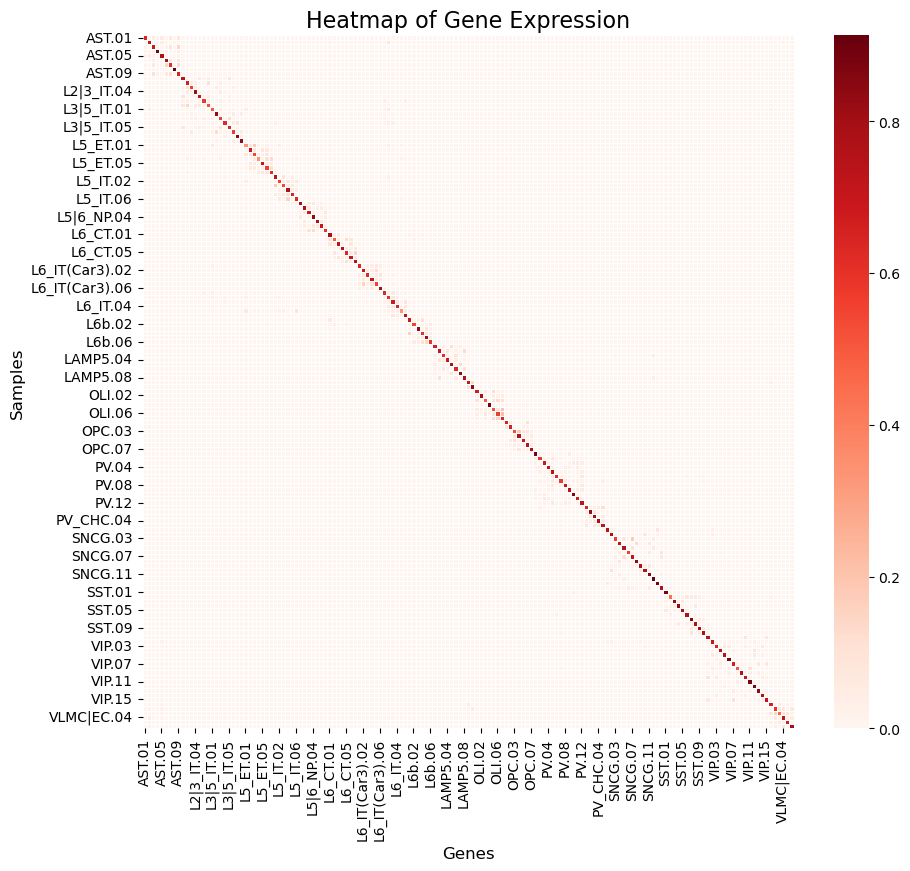

In [20]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt_dt = pd.DataFrame(np.mean(cm_list, axis = 0), index= all_classes, columns=all_classes)
plt.figure(figsize=(10.5, 9))
sns.heatmap(plt_dt, cmap='Reds', annot= False, fmt='.2f', linewidths=0.5)

plt.title('Heatmap of Gene Expression', fontsize=16)
plt.xlabel('Genes', fontsize=12)
plt.ylabel('Samples', fontsize=12)

plt.show()

In [21]:
plt_dt.to_csv("100times_confusion_matrix.tsv",sep = "\t")